# PortfolioPilot - 03 Investor archetypes

**Run the cells in order, top to bottom.** Install the package first (`pip install -e .` from the project root).

Rule for M3: the test sets are created in notebook 01 and then never explored. Every statistic, cap,
table and figure uses **training data only**.

## Step 1 - Setting up

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_pilot.config import Results, ensure_output_dirs, load_config

cfg = load_config()
ensure_output_dirs(cfg)
P, SEED = cfg["paths"], cfg["seed"]
results = Results(P["numbers_file"])    # every count quoted in the report; saved in the last cell
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(P["figures_dir"] / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Step 2 - Features (caps fitted on training data only)

In [2]:
from portfolio_pilot.features import build_partition_features
from portfolio_pilot.prepare import fit_caps
from portfolio_pilot.split import load_partitions

hh = pd.read_csv(P["processed_dir"] / "scf_clean.csv")
parts = load_partitions(hh, P["processed_dir"] / "scf_split_ids.csv")
caps = fit_caps(parts["train"], cfg["scf"]["cap_quantile"], results)     # caps come from training households only
feats = build_partition_features(parts, caps)
tr = feats["train"]
results["features"]

{'caps_from_train': {'dti': 7.32, 'liq_to_income': 4.42},
 'train_ratio_undefined_income_le_0': 18,
 'train_dti_above_cap': 31,
 'train_lti_above_cap': 31,
 'train_fin_zero': 34}

## Step 3 - Choose the number of archetypes - preliminary exploration

### Defining candidate clustering models

This cell defines the clustering algorithms and their shared configuration for each candidate number of archetypes. Keeping model construction in one function ensures that comparisons use consistent initialization, scaling, and random-state behavior.

K-Means and Gaussian mixtures are compared for each k by silhouette score, stability across bootstrap resamples, BIC and smallest group size. Set `clustering.n_bootstrap` to 3 in `config.yaml` for a quick test.

In [3]:
from portfolio_pilot.features import CLUSTER_FEATURES
from portfolio_pilot.models.archetypes import select_k
from portfolio_pilot.prepare import fit_scaler

cl = cfg["clustering"]
scaler, base = fit_scaler(tr, CLUSTER_FEATURES, SEED)
ktab = select_k(tr, scaler, base, CLUSTER_FEATURES, cl["k_range"], cl["n_bootstrap"], SEED)
ktab.to_csv(P["tables_dir"] / "k_selection.csv", index=False)
results.note("target", "k_selection", ktab.round(4).to_dict(orient="records"))
ktab.round(3)

done: kmeans 2


done: kmeans 3


done: kmeans 4


done: kmeans 5


done: kmeans 6


...

done: gmm 3


done: gmm 4


done: gmm 5


done: gmm 6


,method,k,silhouette,bic,stability_ari_mean,stability_ari_sd,min_cluster_share
0,kmeans,2,0.220,NaN,0.654,0.157,0.399
1,kmeans,3,0.246,NaN,0.733,0.245,0.086
2,kmeans,4,0.267,NaN,0.787,0.171,0.086
3,kmeans,5,0.259,NaN,0.942,0.017,0.086
4,kmeans,6,0.264,NaN,0.646,0.083,0.084
5,gmm,2,0.175,42482.818,0.804,0.108,0.447
6,gmm,3,0.140,39341.572,0.218,0.123,0.204
7,gmm,4,0.204,8286.440,0.875,0.087,0.039
8,gmm,5,0.220,6779.090,0.800,0.193,0.024
9,gmm,6,0.167,-6567.865,0.588,0.120,0.029


## Step 4 - Fit the chosen clustering and label every household - Preliminary analysis, NOT IN M3

* *Preliminary five-cluster result to be used later in M4, not part of M3.*
* See Figure 1: Target Balance.
* See Figures 3 and 5 for the features across archetypes, for interpretation and quality checking.

A0 = most conservative ... A(k-1) = most growth-oriented. The model is fitted on training households only; validation and test are only labelled.

In [4]:
from portfolio_pilot.models.archetypes import archetype_profile, assign_archetypes, choose_k, fit_archetypes

if cl["chosen_k"]:
    k = int(cl["chosen_k"])
else:
    k, tied = choose_k(ktab, cl["method"], cl["min_cluster_share"], cl["silhouette_tolerance"])
    print("Tied on silhouette:", tied, "-> most stable:", k)
results.note("target", "chosen", {"method": cl["method"], "k": k})
print("Chosen:", cl["method"], "k =", k)

model, order = fit_archetypes(scaler, base, CLUSTER_FEATURES, cl["method"], k, SEED)
assign_archetypes(feats, model, scaler, order, CLUSTER_FEATURES)

tr = feats["train"]
results.note("target", "train_weighted_share", (tr.groupby("archetype")["weight"].sum() / tr["weight"].sum()).to_dict())
results.note("target", "train_count", tr["archetype"].value_counts().sort_index().to_dict())

# Table 3: weighted medians by archetype
prof = archetype_profile(tr)
prof.to_csv(P["tables_dir"] / "archetype_profile_train.csv")
prof.round(2)

Tied on silhouette: [4, 5, 6] -> most stable: 5
Chosen: kmeans k = 5


,median_age,median_income,median_networth,median_liq,median_dti,median_liq_to_income,median_equity_share,mean_risk_willingness,weighted_share,n_households
archetype,,,,,,,,,,
0,39.0,49297.30,-14149.0,1000.0,0.69,0.02,0.00,0.49,0.09,235.0
1,60.0,44162.16,100700.0,1900.0,0.13,0.04,0.00,0.00,0.29,732.0
2,70.0,109891.89,1272300.0,170000.0,0.00,1.41,0.27,0.82,0.09,341.0
3,50.0,145837.84,677750.0,17000.0,1.17,0.11,0.74,0.93,0.25,954.0
4,45.0,93459.46,184650.0,10000.0,0.41,0.10,0.03,1.06,0.28,790.0


## Step 5 - Save the model-ready files for M4

In [5]:
from portfolio_pilot.config import PROJECT_ROOT
from portfolio_pilot.features import CLASSIFIER_FEATURES

keep = ["household_id", "weight", "archetype"] + sorted(set(CLASSIFIER_FEATURES + CLUSTER_FEATURES))
for name, d in feats.items():
    d[keep].to_csv(P["processed_dir"] / f"scf_{name}.csv", index=False)
print("Saved to", P["processed_dir"].relative_to(PROJECT_ROOT).as_posix())

Saved to data/processed


## Step 6 - Archetype figures

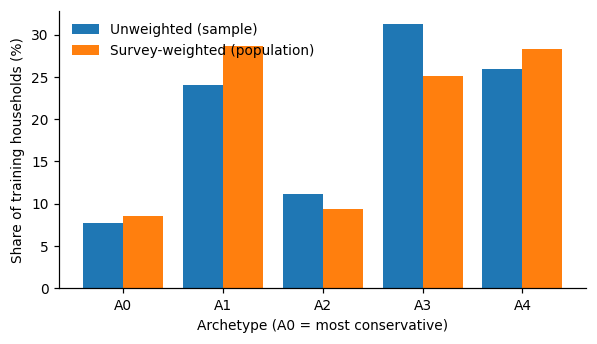

In [6]:
# Figure 1: target balance
arche = sorted(tr["archetype"].unique())
g = tr.groupby("archetype")
x = np.arange(len(arche))
fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.bar(x - 0.2, g.size() / len(tr) * 100, 0.4, label="Unweighted (sample)")
ax.bar(x + 0.2, g["weight"].sum() / tr["weight"].sum() * 100, 0.4, label="Survey-weighted (population)")
ax.set_xticks(x, [f"A{a}" for a in arche])
ax.set_xlabel("Archetype (A0 = most conservative)")
ax.set_ylabel("Share of training households (%)")
ax.legend(frameon=False)
save_fig(fig, "fig01_target_balance")

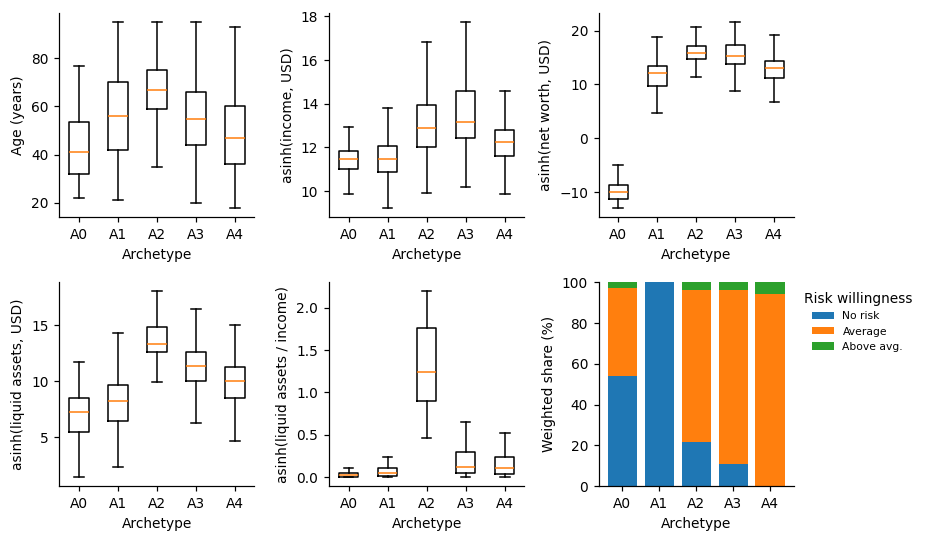

In [7]:
# Figure 3: intake features by archetype
panels = [("age", "Age (years)"), ("asinh_income", "asinh(income, USD)"),
          ("asinh_networth", "asinh(net worth, USD)"), ("asinh_liq", "asinh(liquid assets, USD)"),
          ("asinh_liq_to_income", "asinh(liquid assets / income)")]
fig, axes = plt.subplots(2, 3, figsize=(8.5, 5))
for ax, (c, lab) in zip(axes.flat, panels):
    ax.boxplot([tr.loc[tr["archetype"] == a, c] for a in arche], showfliers=False)
    ax.set_xticks(range(1, len(arche) + 1), [f"A{a}" for a in arche])
    ax.set_xlabel("Archetype")
    ax.set_ylabel(lab)
ax = axes.flat[-1]
ct = pd.crosstab(tr["archetype"], tr["risk_willingness"], values=tr["weight"],
                 aggfunc="sum", normalize="index") * 100
bottom = np.zeros(len(ct))
for r, name in zip(ct.columns, ["No risk", "Average", "Above avg."]):
    ax.bar([f"A{a}" for a in ct.index], ct[r], bottom=bottom, label=name)
    bottom += ct[r].to_numpy()
ax.set_xlabel("Archetype")
ax.set_ylabel("Weighted share (%)")
ax.legend(title="Risk willingness", frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1, 1))
save_fig(fig, "fig03_features_by_archetype")

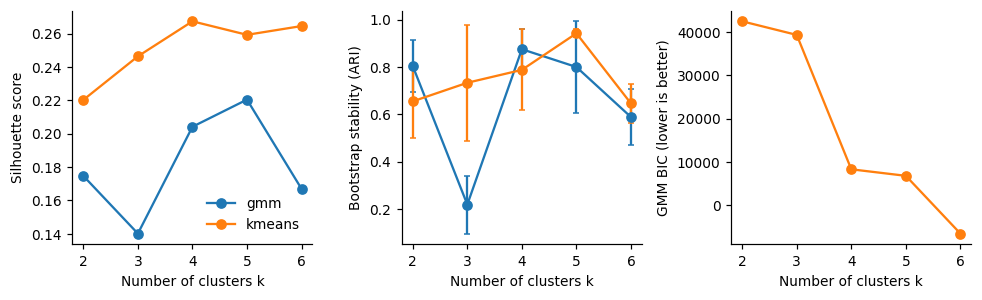

In [8]:
# Figure 5: choosing k
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8))
for m, d in ktab.groupby("method"):
    axes[0].plot(d["k"], d["silhouette"], marker="o", label=m)
    axes[1].errorbar(d["k"], d["stability_ari_mean"], yerr=d["stability_ari_sd"], marker="o", capsize=2, label=m)
gm = ktab[ktab["method"] == "gmm"]
axes[2].plot(gm["k"], gm["bic"], marker="o", color="C1")
for a, lab in zip(axes, ["Silhouette score", "Bootstrap stability (ARI)", "GMM BIC (lower is better)"]):
    a.set_xlabel("Number of clusters k")
    a.set_ylabel(lab)
axes[0].legend(frameon=False)
save_fig(fig, "fig05_k_selection")

## Save the numbers quoted in the report

In [9]:
from portfolio_pilot.config import PROJECT_ROOT

results.save()
print("Saved", P["numbers_file"].relative_to(PROJECT_ROOT).as_posix())

Saved reports/numbers.json
